In [149]:
import pandas as pd
import numpy as np
import seaborn as sb
#create a data frame 
carSalesDF = pd.read_csv("car-sales.csv")
#Since the data frame contains car sales from all over the world, the df USDF will contain car sales for the U.S
USDF = carSalesDF[carSalesDF['Code'] == "USA"]
USDF


,Entity,Code,Year,Electric cars sold,Non-electric car sales
391,United States,USA,2011,17800,11848866.0
392,United States,USA,2012,54000,12803143.0
393,United States,USA,2013,97000,13564972.0
394,United States,USA,2014,118000,15206676.0
395,United States,USA,2015,114000,16171715.0
396,United States,USA,2016,160000,16001616.0
397,United States,USA,2017,194000,14729077.0
398,United States,USA,2018,360000,15292174.0
399,United States,USA,2019,325000,15151191.0
400,United States,USA,2020,294000,12488609.0


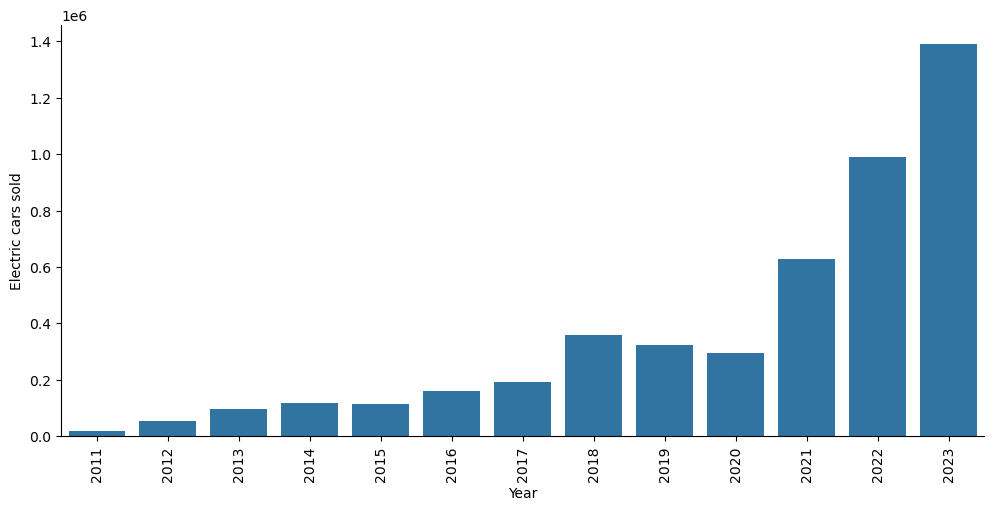

In [151]:
#This histogram shows that the sales of electric vehicles have been increasing over the years 


sb.catplot(x="Year",y="Electric cars sold",data=USDF , aspect=2,kind="bar", ).set_xticklabels(rotation=90)

In [153]:
#What is the average annual cost of charging an electric vehicle for killowat-hour? 

In [155]:
# https://afdc.energy.gov/data/categories/vehicles--2
import requests
apiKey = "e5Cdl0LhQqLxB5gg0jHICDjAleMXbFwg0E9MEaAs"
#this request gives the average cost KHW per state annually
Cost= requests.get("https://api.eia.gov/v2/electricity/retail-sales/data/?api_key=e5Cdl0LhQqLxB5gg0jHICDjAleMXbFwg0E9MEaAs&frequency=annual&data[0]=price&facets[sectorid][]=RES&start=2012&end=2024&sort[0][column]=period&sort[0][direction]=desc&offset=0&length=5000").json()

In [157]:
# costDF is a dataframe that contains the average electricity pricing information across US states for residential use for years 2012-2023
costDF = pd.DataFrame(Cost['response']['data'])
costDF


,period,stateid,stateDescription,sectorid,sectorName,price,price-units
0,2023,NEW,New England,RES,residential,28.73,cents per kilowatt-hour
1,2023,NM,New Mexico,RES,residential,13.85,cents per kilowatt-hour
2,2023,NJ,New Jersey,RES,residential,17.7,cents per kilowatt-hour
3,2023,DC,District of Columbia,RES,residential,16.45,cents per kilowatt-hour
4,2023,DE,Delaware,RES,residential,15.73,cents per kilowatt-hour
...,...,...,...,...,...,...,...
739,2012,DE,Delaware,RES,residential,13.58,cents per kilowatt-hour
740,2012,HI,Hawaii,RES,residential,37.34,cents per kilowatt-hour
741,2012,ID,Idaho,RES,residential,8.67,cents per kilowatt-hour
742,2012,IA,Iowa,RES,residential,10.82,cents per kilowatt-hour


In [159]:
#to avoid errors, this replaces any character that is not a digit into ''
# costDF['price'] = costDF['price'].replace(r'[^0-9.]', '')
costDF['price'] = costDF['price'].replace('[^d.]', '')
costDF['price'] = pd.to_numeric(costDF['price'], errors='coerce')
#groups by the 'period' columns and calculates the average price by using agg function 'mean' to the period column 
AvgCostPerK = costDF.groupby("period").agg({"price":"mean"})
# Average annual cost of a kilowatt-hour in the United States for an electric vehicle the price units are cents per kilowatt-hour
AvgCostPerK

,price
period,
2012,12.613387
2013,12.859516
2014,13.316613
2015,13.419516
2016,13.355161
2017,13.723710
2018,13.856452
2019,13.991452
2020,14.029516


In [161]:
# What was the average cost of charging an electric vehicle anually? 

In [163]:
#calculates the average cost per mile 
#on average, electric vehicles consume about 0.3 khw per mile 
AvgCostPerK['annualcost']  = (((AvgCostPerK['price'] * 0.3) * 0.01 )* 12000).round(2)
AvgCostPerK

,price,annualcost
period,,
2012,12.613387,454.08
2013,12.859516,462.94
2014,13.316613,479.40
2015,13.419516,483.10
2016,13.355161,480.79
2017,13.723710,494.05
2018,13.856452,498.83
2019,13.991452,503.69
2020,14.029516,505.06


In [165]:
# what about for a fuel-powered car? 
#costGas gets gasoline prices per  state anually
costGas= requests.get("https://api.eia.gov/v2/petroleum/pri/gnd/data/?api_key=e5Cdl0LhQqLxB5gg0jHICDjAleMXbFwg0E9MEaAs&frequency=annual&data[0]=value&facets[product][]=EPMR&facets[duoarea][]=NUS&start=2011&end=2024&sort[0][column]=period&sort[0][direction]=desc&offset=0&length=5000").json()
costGas.keys()

dict_keys(['response', 'request', 'apiVersion', 'ExcelAddInVersion'])

In [166]:
# costGasDF is a data frame that contains the average gasoline pricing information across US states for years 2012-2023
costGasDF = pd.DataFrame(costGas['response']['data']).sort_values(by = "period", ascending = True)
costGasDF


,period,duoarea,area-name,product,product-name,process,process-name,series,series-description,value,units
11,2012,NUS,U.S.,EPMR,Regular Gasoline,PTE,Retail Sales,EMM_EPMR_PTE_NUS_DPG,U.S. Regular All Formulations Retail Gasoline ...,3.618,$/GAL
10,2013,NUS,U.S.,EPMR,Regular Gasoline,PTE,Retail Sales,EMM_EPMR_PTE_NUS_DPG,U.S. Regular All Formulations Retail Gasoline ...,3.505,$/GAL
9,2014,NUS,U.S.,EPMR,Regular Gasoline,PTE,Retail Sales,EMM_EPMR_PTE_NUS_DPG,U.S. Regular All Formulations Retail Gasoline ...,3.358,$/GAL
8,2015,NUS,U.S.,EPMR,Regular Gasoline,PTE,Retail Sales,EMM_EPMR_PTE_NUS_DPG,U.S. Regular All Formulations Retail Gasoline ...,2.429,$/GAL
7,2016,NUS,U.S.,EPMR,Regular Gasoline,PTE,Retail Sales,EMM_EPMR_PTE_NUS_DPG,U.S. Regular All Formulations Retail Gasoline ...,2.143,$/GAL
6,2017,NUS,U.S.,EPMR,Regular Gasoline,PTE,Retail Sales,EMM_EPMR_PTE_NUS_DPG,U.S. Regular All Formulations Retail Gasoline ...,2.415,$/GAL
5,2018,NUS,U.S.,EPMR,Regular Gasoline,PTE,Retail Sales,EMM_EPMR_PTE_NUS_DPG,U.S. Regular All Formulations Retail Gasoline ...,2.719,$/GAL
4,2019,NUS,U.S.,EPMR,Regular Gasoline,PTE,Retail Sales,EMM_EPMR_PTE_NUS_DPG,U.S. Regular All Formulations Retail Gasoline ...,2.604,$/GAL
3,2020,NUS,U.S.,EPMR,Regular Gasoline,PTE,Retail Sales,EMM_EPMR_PTE_NUS_DPG,U.S. Regular All Formulations Retail Gasoline ...,2.168,$/GAL
2,2021,NUS,U.S.,EPMR,Regular Gasoline,PTE,Retail Sales,EMM_EPMR_PTE_NUS_DPG,U.S. Regular All Formulations Retail Gasoline ...,3.008,$/GAL


In [169]:
#to avoid errors, this replaces any character that is not a digit into ''

costGasDF['value'] = costGasDF['value'].replace('[^d.]', '')
costGasDF['value'] = pd.to_numeric(costGasDF['value'], errors='coerce')

#groups by the 'period' columns and calculates the average price by using agg function 'mean' to the period column 
AvgCostPerG = costGasDF.groupby("period").agg({"value":"mean"})
# Average annual cost of a kilowatt-hour in the United States for an electric vehicle the price units are cents per kilowatt-hour
AvgCostPerG

,value
period,
2012,3.618
2013,3.505
2014,3.358
2015,2.429
2016,2.143
2017,2.415
2018,2.719
2019,2.604
2020,2.168


In [171]:
# What is the average cost of using gas annually 
#0.04:  average number of gallons consumed per gallon 
#12000:  average number of miles driven annually
AvgCostPerG['annualcost']  = ((AvgCostPerG['value'] * 0.04) * 12000).round(2)
AvgCostPerG

,value,annualcost
period,,
2012,3.618,1736.64
2013,3.505,1682.40
2014,3.358,1611.84
2015,2.429,1165.92
2016,2.143,1028.64
2017,2.415,1159.20
2018,2.719,1305.12
2019,2.604,1249.92
2020,2.168,1040.64


<Axes: xlabel='period', ylabel='annualcost'>

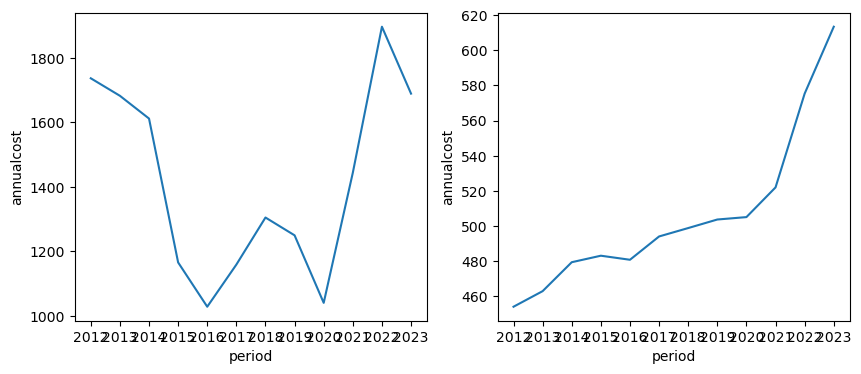

In [173]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
rcParams["figure.figsize"] = 10,4

fig, (ax1,ax2) = plt.subplots(ncols=2,sharey=False)
sb.lineplot(x="period",y="annualcost",data=AvgCostPerG,ax=ax1)
sb.lineplot(x="period",y="annualcost",data=AvgCostPerK,ax=ax2)

In [1]:
#what is the co2 commission of vehicles in the US 
vehiclesDF = pd.read_csv("vehicles.csv")
vehiclesDF.columns
vehiclesDF

NameError: name 'pd' is not defined

In [353]:
#to make my dataframe smaller and simplier, the dataframe will only have id ,fuelType, co2 , co2A, make, model 
vehiclesDF=vehiclesDF.drop(columns = ['barrels08', 'barrelsA08', 'charge120', 'charge240', 'city08',
       'city08U', 'cityA08', 'cityA08U', 'cityCD', 'cityE', 'cityUF', 'co2',
       'co2A','co2TailpipeAGpm',  'comb08', 'comb08U',
       'combA08', 'combA08U', 'combE', 'combinedCD', 'combinedUF', 'cylinders',
       'displ', 'drive', 'engId', 'eng_dscr', 'feScore', 'fuelCost08',
       'fuelCostA08',  'ghgScore', 'ghgScoreA',
       'highway08', 'highway08U', 'highwayA08', 'highwayA08U', 'highwayCD',
       'highwayE', 'highwayUF', 'hlv', 'hpv',  'lv2', 'lv4', 'mpgData', 'phevBlended', 'pv2', 'pv4', 'range', 'rangeCity',
       'rangeCityA', 'rangeHwy', 'rangeHwyA', 'trany', 'UCity', 'UCityA',
       'UHighway', 'UHighwayA', 'VClass', 'year', 'youSaveSpend', 'baseModel',
       'guzzler', 'trans_dscr', 'tCharger', 'sCharger', 'atvType', 
       'rangeA', 'evMotor', 'mfrCode', 'c240Dscr', 'charge240b', 'c240bDscr',
       'createdOn', 'modifiedOn', 'startStop', 'phevCity', 'phevHwy',
       'phevComb'])


In [355]:
vehiclesDF

,co2TailpipeGpm,fuelType,fuelType1,id,make,model,fuelType2
0,423.190476,Regular,Regular Gasoline,1,Alfa Romeo,Spider Veloce 2000,NaN
1,807.909091,Regular,Regular Gasoline,10,Ferrari,Testarossa,NaN
2,329.148148,Regular,Regular Gasoline,100,Dodge,Charger,NaN
3,807.909091,Regular,Regular Gasoline,1000,Dodge,B150/B250 Wagon 2WD,NaN
4,467.736842,Premium,Premium Gasoline,10000,Subaru,Legacy AWD Turbo,NaN
...,...,...,...,...,...,...,...
48226,403.954545,Regular,Regular Gasoline,9995,Subaru,Legacy,NaN
48227,386.391304,Regular,Regular Gasoline,9996,Subaru,Legacy,NaN
48228,423.190476,Regular,Regular Gasoline,9997,Subaru,Legacy AWD,NaN
48229,423.190476,Regular,Regular Gasoline,9998,Subaru,Legacy AWD,NaN


In [404]:
# regularGasVehiclesDF has vehicles that has regular and premium fuel type
regularGasVehiclesDF = vehiclesDF[vehiclesDF['fuelType'].apply(lambda x: x in ['Regular', 'Premium'])]

In [359]:
#which vehicles has the highest amount of tailpipe co2 emissions? 
HighestDf = regularGasVehiclesDF.sort_values("co2TailpipeGpm", ascending = False).head(10)

In [389]:
HighestDf 

,co2TailpipeGpm,fuelType,fuelType1,id,make,model,fuelType2
42974,1269.571429,Premium,Premium Gasoline,5267,Lamborghini,Countach,NaN
34522,1269.571429,Premium,Premium Gasoline,4141,Lamborghini,Countach,NaN
21057,1269.571429,Premium,Premium Gasoline,2914,Lamborghini,Countach,NaN
7901,1269.571429,Premium,Premium Gasoline,1711,Lamborghini,Countach,NaN
44248,1269.571429,Premium,Premium Gasoline,6413,Lamborghini,Countach,NaN
19882,1110.875000,Regular,Regular Gasoline,28062,Maserati,Quattroporte,NaN
19652,1110.875000,Regular,Regular Gasoline,27856,Rolls-Royce,Corniche,NaN
9229,1110.875000,Premium,Premium Gasoline,18305,Ferrari,Enzo Ferrari,NaN
11734,1110.875000,Regular,Regular Gasoline,2056,Rolls-Royce,Camargue,NaN
19790,1110.875000,Regular,Regular Gasoline,27980,Rolls-Royce,Camargue,NaN


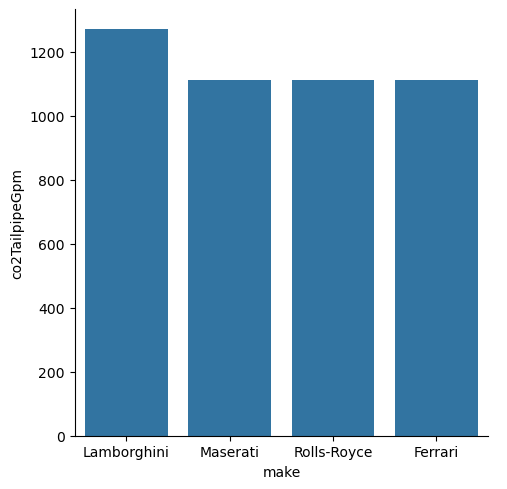

In [391]:

sb.catplot(x="make",y="co2TailpipeGpm",data= HighestDf ,kind="bar" , height=5, aspect=1)

In [393]:
#which vehicles have the smallest amount of tailpipe co2 emissions? 
minDF = regularGasVehiclesDF.sort_values("co2TailpipeGpm", ascending = True).head(10)

In [395]:
minDF

,co2TailpipeGpm,fuelType,fuelType1,id,make,model,fuelType2
36897,151.0,Regular,Regular Gasoline,43571,Hyundai,Ioniq Blue,NaN
37510,151.0,Regular,Regular Gasoline,44138,Hyundai,Ioniq Blue,NaN
35439,154.0,Regular,Regular Gasoline,42243,Hyundai,Ioniq Blue,NaN
31285,154.0,Regular,Regular Gasoline,38485,Hyundai,Ioniq Blue,NaN
33560,154.0,Regular,Regular Gasoline,40536,Hyundai,Ioniq Blue,NaN
32539,154.0,Regular,Regular Gasoline,39614,Hyundai,Ioniq Blue,NaN
39963,155.0,Regular,Regular Gasoline,46359,Toyota,Prius,NaN
40941,155.0,Regular,Regular Gasoline,47243,Toyota,Prius,NaN
29824,158.0,Regular,Regular Gasoline,37164,Toyota,Prius Eco,NaN
37447,158.0,Regular,Regular Gasoline,44081,Toyota,Prius Eco,NaN


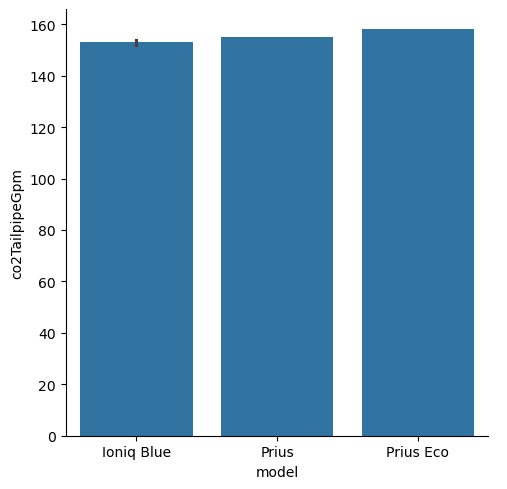

In [401]:

sb.catplot(x="model",y="co2TailpipeGpm",data= minDF ,kind="bar" , height=5, aspect=1)

In [414]:
#average co2 emmisions vehicles 
co2EmissionsforRegular = regularGasVehiclesDF['co2TailpipeGpm'].mean()
co2EmissionsDF = pd.DataFrame(columns = ['VehicleType' , 'co2'])
co2EmissionsDF.loc[0] = ['Regular', co2EmissionsforRegular]

In [416]:
co2EmissionsDF

,VehicleType,co2
0,Regular,460.347607


In [422]:
#https://ourworldindata.org/travel-carbon-footprint 
co2EmissionsforEV = pd.read_csv("carbon-footprint-travel-mode.csv")
co2EmissionsforEV

,Entity,Code,Year,Transport emissions per kilometer travelled
0,Bus (average),NaN,2022,96.50
1,Bus (local London),NaN,2022,79.36
2,Coach (bus),NaN,2022,27.33
3,Diesel car,NaN,2022,170.82
4,Domestic flight,NaN,2022,245.87
5,Electric car,NaN,2022,47.09
6,Eurostar (to Paris),NaN,2022,4.46
7,Ferry (foot passenger),NaN,2022,18.74
8,London Underground,NaN,2022,27.81
9,Long-haul flight,NaN,2022,147.87


In [424]:
#converting emmisions per mile traveled 
# it is multiplied by  1.609344 because that the amount of kilometers in a mile 
co2EmissionsforEV["Transport emissions per mile travelled"] = co2EmissionsforEV["Transport emissions per kilometer travelled"] * 1.609344

In [426]:
co2EmissionsforEV

,Entity,Code,Year,Transport emissions per kilometer travelled,Transport emissions per mile travelled
0,Bus (average),NaN,2022,96.50,155.301696
1,Bus (local London),NaN,2022,79.36,127.717540
2,Coach (bus),NaN,2022,27.33,43.983372
3,Diesel car,NaN,2022,170.82,274.908142
4,Domestic flight,NaN,2022,245.87,395.689409
5,Electric car,NaN,2022,47.09,75.784009
6,Eurostar (to Paris),NaN,2022,4.46,7.177674
7,Ferry (foot passenger),NaN,2022,18.74,30.159107
8,London Underground,NaN,2022,27.81,44.755857
9,Long-haul flight,NaN,2022,147.87,237.973697


In [436]:
co2EmissionsDF.loc[1] = ['Electric Vehicle', co2EmissionsforEV.iloc[5,3]]

In [438]:
#the co2emmisions per vehicle type per gram per mile 
co2EmissionsDF

,VehicleType,co2
0,Regular,460.347607
1,Electric Vehicle,47.090000


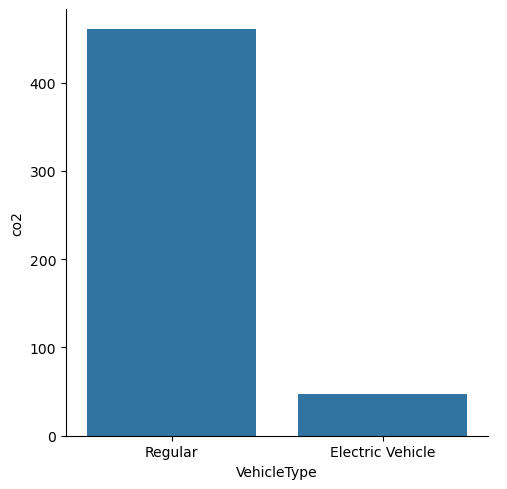

In [444]:
sb.catplot(x = "VehicleType" , y = "co2" , data = co2EmissionsDF , kind = "bar")

In [ ]:
#